# https://youtu.be/tNOu-SEacNU?t=963

Imagine start all points at x=0, then randomly they either go -1 or +1

after some iterations, count for each x, plot a histogram

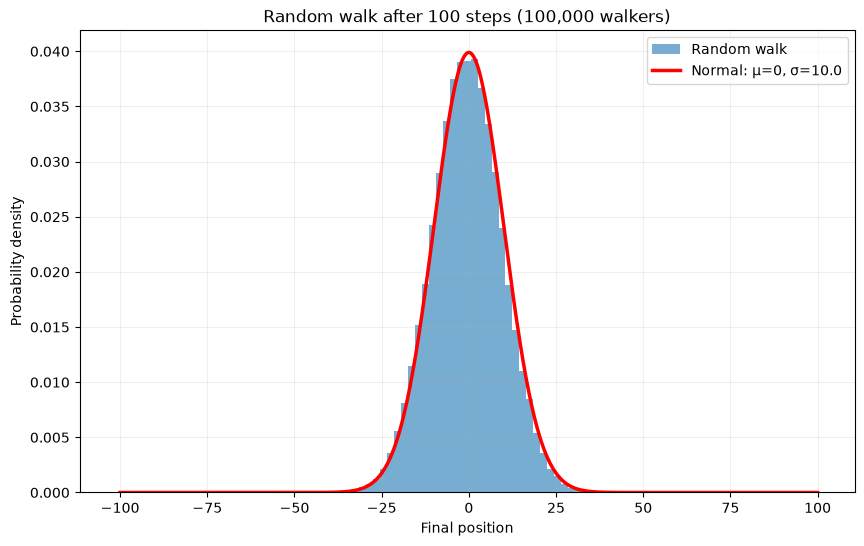

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

rng = np.random.default_rng(42)

# Simulation parameters
num_walkers = 100_000
num_steps = 100

# All walkers start at x = 0
positions = np.zeros(num_walkers)

# Random walk: each step is either -1 or +1
for _ in range(num_steps):
    steps = rng.choice([-1, 1], size=num_walkers)
    positions += steps

# Theoretical normal distribution
mu = 0
sigma = np.sqrt(num_steps)

# Plot histogram
plt.figure(figsize=(10, 6))

plt.hist(
    positions,
    bins=np.arange(-num_steps - 1.5, num_steps + 2.5, 2),
    density=True,
    alpha=0.6,
    label="Random walk"
)

# Overlay normal density
x = np.linspace(-num_steps, num_steps, 1000)
plt.plot(
    x,
    norm.pdf(x, mu, sigma),
    color="red",
    linewidth=2.5,
    label=f"Normal: μ={mu}, σ={sigma:.1f}"
)

plt.xlabel("Final position")
plt.ylabel("Probability density")
plt.title(f"Random walk after {num_steps} steps ({num_walkers:,} walkers)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

# normal best because

Two arguments 
(1) Generative: Summed fluctuations tend towards normal 
distribution 
(2) Inferential: For estimating mean and variance, normal 
distribution is least informative distribution (maxent) ; fewest assumptions


Variable does not have to be normally distributed for normal 
model to be useful. It’s a machine for estimating mean/variance.

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

# Load CSV
df = pd.read_csv("./data/Howell1.csv", sep=";")

df = df[df["age"] >= 18]

df

,height,weight,age,male
0,151.765,47.825606,63.0,1
1,139.700,36.485807,63.0,0
2,136.525,31.864838,65.0,0
3,156.845,53.041914,41.0,1
4,145.415,41.276872,51.0,0
...,...,...,...,...
534,162.560,47.031821,27.0,0
537,142.875,34.246196,31.0,0
540,162.560,52.163080,31.0,1
541,156.210,54.062497,21.0,0


352


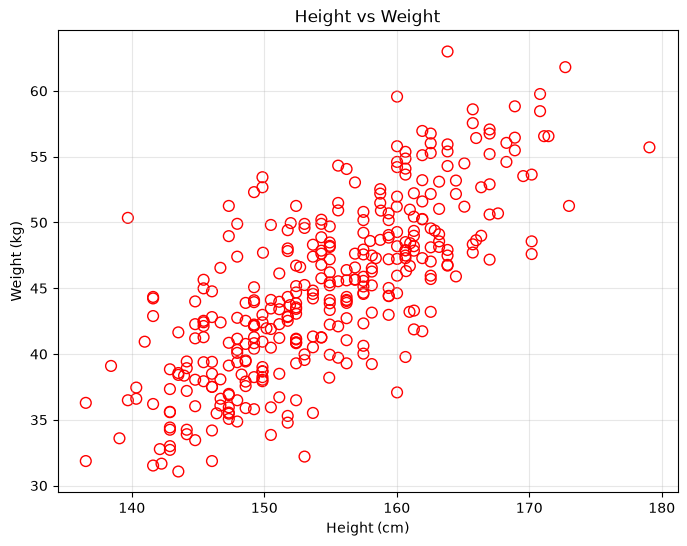

In [16]:
import pandas as pd
import matplotlib.pyplot as plt


# Scatter plot: height vs weight
plt.figure(figsize=(8, 6))

plt.scatter(
    df["height"],
    df["weight"],
    facecolors="none",
    edgecolors="red",
    marker="o",
    s=60
)

plt.xlabel("Height (cm)")
plt.ylabel("Weight (kg)")
plt.title("Height vs Weight")
plt.grid(alpha=0.3)
print(len(df))
plt.show()

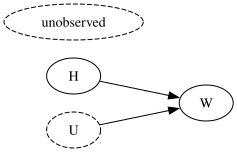

In [13]:
from graphviz import Digraph
from IPython.display import display

import util
from importlib import reload
# in case we are editinng
reload(util)


util.draw_causal_graph(
    edge_list=[
        ("H", "W"),
        ("U", "W")
    ],
    node_props={
        "U": {"style": "dashed"},
        "unobserved": {"style": "dashed"}
    },
    graph_direction="LR"
)
# see https://github.com/dustinstansbury/statistical-rethinking-2023/blob/main/Lecture%2003%20-%20Geocentric%20Models.ipynb


$ W = f(H, U) $

Weight is some function of height and unobserved stuff

$ W = {\beta}H + U $

For adults, weight is a proportion of height plus the influence 
of unobserved causes

In [9]:
def sim_weight(H, b, sd, rng=rng):
    # H is cm
    
    # b: regression slope; expected increase in weight for each
    # one-unit increase in height (e.g. kg per cm).

    # Random noise for each individual:
    # loc=0: mean of the noise distribution is zero
    # scale=sd: standard deviation of the noise (weight units, e.g. kg)    
    # Variance of the noise is sd**2.
    U = rng.normal(loc=0, scale=sd, size=len(H))

    # Weight = slope * height + random noise
    W = b * H + U

    return W

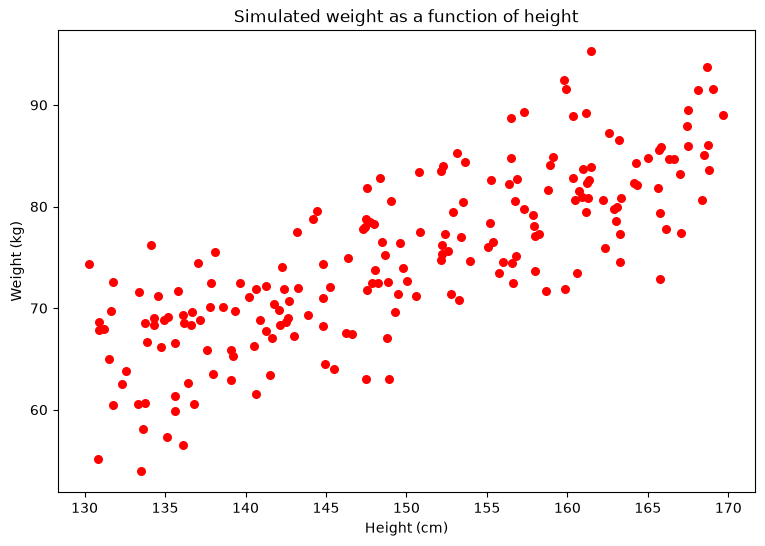

In [11]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)


# Simulate heights for 200 individuals, uniformly distributed
# between 130 cm and 170 cm.
H = rng.uniform(low=130, high=170, size=200)

# Simulate weights using b=0.5 and a noise standard deviation of 5 kg / variance of 25 kg
W = sim_weight(H, b=0.5, sd=5, rng=rng)

# Plot the synthetic individuals.
plt.figure(figsize=(9, 6))
plt.scatter(H, W, color="red", s=30)

plt.xlabel("Height (cm)")
plt.ylabel("Weight (kg)")
plt.title("Simulated weight as a function of height")
plt.show()

Variables are deterministic or some distribution

$$
\begin{aligned}
W_i &= {\beta}H_i + U_i
\\
U_i &\sim \text{Normal}(0, \sigma)
\\
H_i &\sim \text{Uniform}(130, 170)
\end{aligned}
\\[2em]

\underbrace{\operatorname{E}[W_i \mid H_i]}_{\text{Avg weight conditional on height}}
=  \underbrace{\alpha}_{\text{intercept}}
+
\underbrace{\beta H_i}_{\text{slope}}

\\[3em]

\underbrace{
Pr(\alpha,\beta,\sigma \mid H_i,W_i)
}_{\text{Posterior probability of specific regression line}}
=
\frac{
\overbrace{
Pr(W_i \mid H_i,\alpha,\beta,\sigma)
}^{\text{Likelihood; garden forking data}}
\;
\overbrace{
Pr(\alpha,\beta,\sigma)
}^{\text{Prior}}
}{
\underbrace{
Z
}_{\text{Normalizing constant}}
}
\\[2em]
W_i \sim \text{Normal}({\mu}_i, \sigma)

\\
{\mu}_i = \alpha + {\beta}H_i

$$

garden forking data  / likelihood

proportional on number of ways we could see the observations conditional on an exact line
given line alpha beta sigma, how many ways could we produce $W_i$ given $H_i$

Prior

previous data could have produced a specific set of unknowns

* i are individual observations
* ~ is distributed as
* = is determinisic relationship

See https://youtu.be/tNOu-SEacNU?t=2445
https://speakerdeck.com/rmcelreath/statistical-rethinking-2023-lecture-03?slide=48

In [17]:
from pathlib import Path

import pymc as pm
import numpy as np
import matplotlib.pyplot as plt

# https://speakerdeck.com/rmcelreath/statistical-rethinking-2023-lecture-03?slide=52
# number of width/height samples
sample_sizes = [1, 2, 3, 10, 20, 89]

posterior_samples = {}

for n in sample_sizes:
    with pm.Model() as model:
        # assumping alpha is 0
        beta = pm.Uniform("beta", lower=0, upper=1)

        W_obs = pm.Normal(
            "W_obs",
            mu=beta * H[:n],
            sigma=5,
            observed=W[:n]
        )

        trace = util.sample_or_load(
                lambda: pm.sample(
            draws=2000,
            tune=1000,
            chains=4,
            target_accept=0.95,
            random_seed=42,
            progressbar=False
        ), Path(f"chap3_52_{n}.trace"))

    posterior_samples[n] = (
        trace.posterior["beta"].values.flatten()
    )

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta]
Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 3 seconds.
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta]
Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 2 seconds.
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta]
Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 3 seconds.
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta]
Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 3 seconds.
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta]
Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws tot

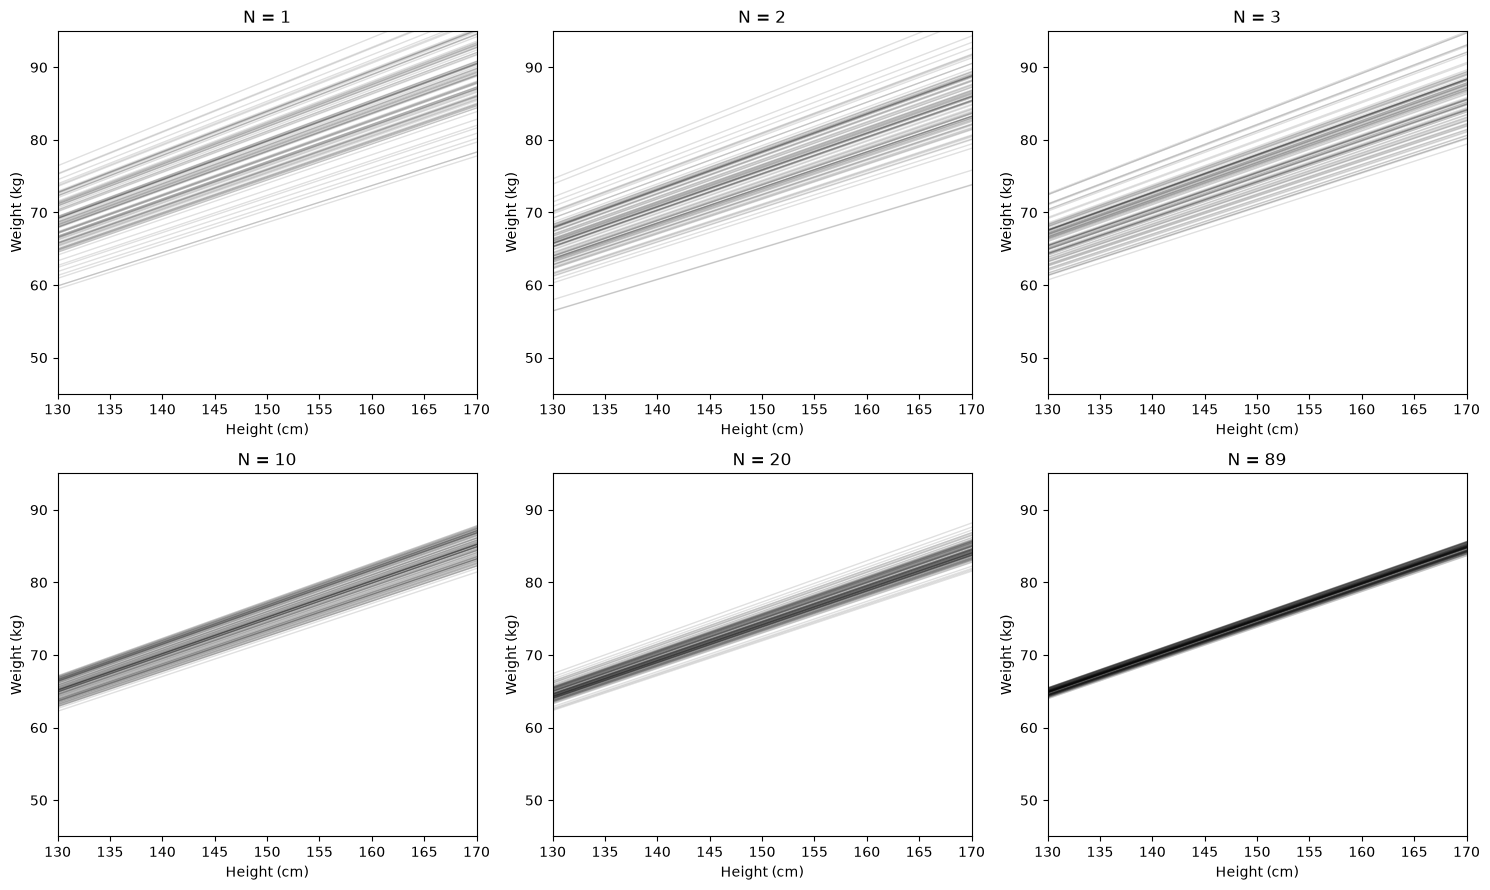

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

H_grid = np.linspace(130, 170, 100)

for ax, n in zip(axes.flat, sample_sizes):
    betas = posterior_samples[n]

    for beta_sample in betas[:100]:
        ax.plot(
            H_grid,
            beta_sample * H_grid,
            color="black",
            alpha=0.12,
            linewidth=1
        )

    ax.set_title(f"N = {n}")
    ax.set_xlabel("Height (cm)")
    ax.set_ylabel("Weight (kg)")
    ax.set_xlim(130, 170)
    ax.set_ylim(45, 95)

plt.tight_layout()
plt.show()

Posterior is multivariate gaussian

shifting from generative model to statistical model

$$
\begin{aligned}
W_i &= {\text{Normal}}(\mu_i, \sigma)
\\
\mu_i &= \alpha + {\beta}H_i
\\
\alpha &\sim \text{Normal}(0, 10)
\\
\beta &\sim \text{Uniform(0, 1)}
\\
\sigma &\sim \text{Uniform(0, 10)}
\end{aligned}
$$

alpha / beta / sigma are priors

prior and posterior distributions are the same thing

goal is to constrain softly the scope of the model

prior predictive distribution

beta is positive because weight(kg) is less than height(cm)

sigma must be positive

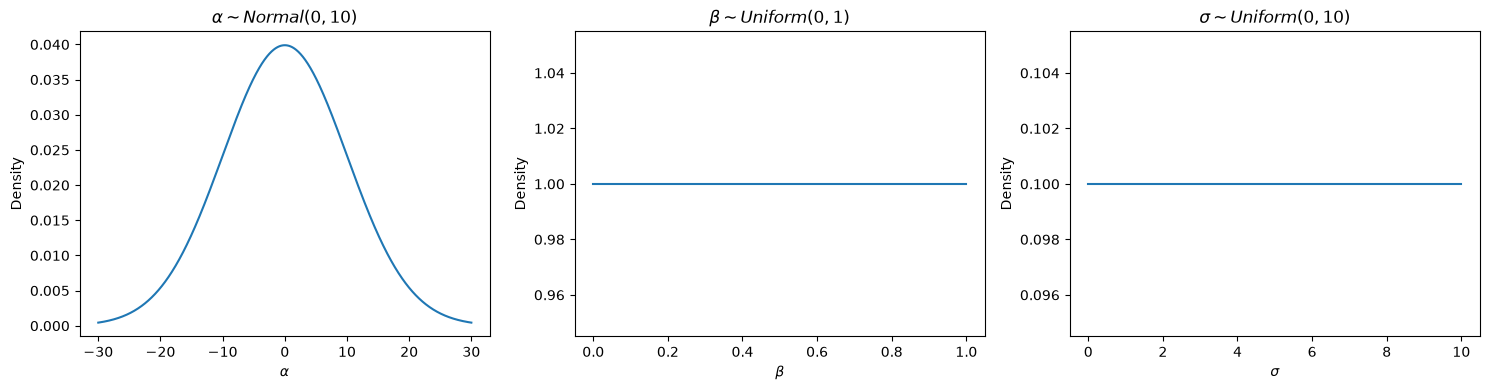

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, uniform

# Parameter ranges
alpha = np.linspace(-30, 30, 1000)
beta = np.linspace(0, 1, 1000)
sigma = np.linspace(0, 10, 1000)

# Prior probability densities
alpha_pdf = norm.pdf(alpha, loc=0, scale=10)
beta_pdf = uniform.pdf(beta, loc=0, scale=1)
sigma_pdf = uniform.pdf(sigma, loc=0, scale=10)

# Plot
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(alpha, alpha_pdf)
axes[0].set_title(r"$\alpha \sim Normal(0, 10)$")
axes[0].set_xlabel(r"$\alpha$")
axes[0].set_ylabel("Density")

axes[1].plot(beta, beta_pdf)
axes[1].set_title(r"$\beta \sim Uniform(0, 1)$")
axes[1].set_xlabel(r"$\beta$")
axes[1].set_ylabel("Density")

axes[2].plot(sigma, sigma_pdf)
axes[2].set_title(r"$\sigma \sim Uniform(0, 10)$")
axes[2].set_xlabel(r"$\sigma$")
axes[2].set_ylabel("Density")

plt.tight_layout()
plt.show()

# A prior probability density function (PDF) integrates to 1 over its parameter space:
# For discrete parameters, a prior probability mass function (PMF) sums to 1.  

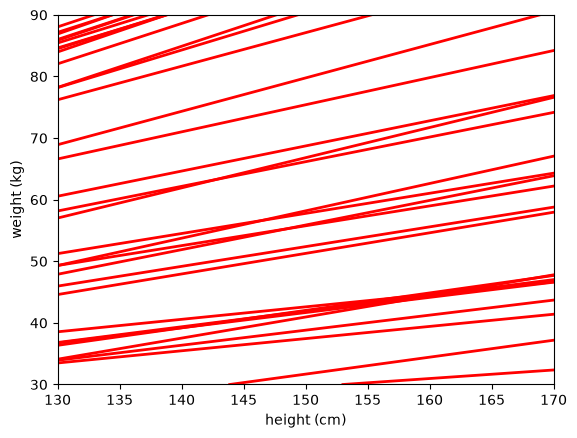

In [22]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

n = 1_000

a = rng.normal(loc=0, scale=10, size=n)
b = rng.uniform(low=0, high=1, size=n)

fig, ax = plt.subplots()

ax.set_xlim(130, 170)
ax.set_ylim(30, 90)
ax.set_xlabel("height (cm)")
ax.set_ylabel("weight (kg)")

for j in range(50):
    ax.axline((0, a[j]), slope=b[j], linewidth=2, color="red")

plt.show()

In [6]:
# https://youtu.be/tNOu-SEacNU?t=3733
# https://speakerdeck.com/rmcelreath/statistical-rethinking-2023-lecture-03?slide=64

import numpy as np
import pymc as pm
import arviz as az
import pandas as pd
import util
from pathlib import Path 
from importlib import reload
# in case we are editinng
reload(util)

# Simulate data
rng = np.random.default_rng(42)

H = rng.uniform(low=130, high=170, size=10)

# repeating definition
def sim_weight(H, b, sd, rng=rng):
    # H is cm
    
    # b: regression slope; expected increase in weight for each
    # one-unit increase in height (e.g. kg per cm).

    # Random noise for each individual:
    # loc=0: mean of the noise distribution is zero
    # scale=sd: standard deviation of the noise (weight units, e.g. kg)    
    # Variance of the noise is sd**2.
    U = rng.normal(loc=0, scale=sd, size=len(H))

    # Weight = slope * height + random noise
    W = b * H + U

    return W

W = sim_weight(H, b=0.5, sd=5, rng=rng)

# Define and run the model
with pm.Model() as m3_1:
    # variation is sigma squared
    a = pm.Normal("a", mu=0, sigma=10) 
    b = pm.Uniform("b", lower=0, upper=1)
    sigma = pm.Uniform("sigma", lower=0, upper=10)

    mu = a + b * H

    W_obs = pm.Normal("W_obs", mu=mu, sigma=sigma, observed=W)

    trace = util.sample_or_load(
                lambda: pm.sample(
        draws=2000,
        tune=1000,
        chains=4,
        random_seed=93,
        target_accept=0.95
    ), Path(f"chap3_64.trace"))

# Posterior summary
az.summary(trace, var_names=["a", "b", "sigma"])

posterior = trace.posterior

results = {}

for name in ["a", "b", "sigma"]:
    samples = posterior[name].values.flatten()

    results[name] = {
        "mean": samples.mean(),
        "sd": samples.std(ddof=1),
        "5.5%": np.quantile(samples, 0.055),
        "94.5%": np.quantile(samples, 0.945),
    }

pd.DataFrame(results).T

,mean,sd,5.5%,94.5%
a,6.252779,8.775618,-8.227748,19.920331
b,0.467334,0.057646,0.377238,0.561049
sigma,4.151818,1.246218,2.627331,6.494843


In [1]:
import ipywidgets as widgets
from IPython.display import display

display(widgets.IntSlider())

IntSlider(value=0)

In [2]:
# Now use real data
# # Load CSV
import numpy as np
import pymc as pm
import arviz as az
import pandas as pd
import util
from pathlib import Path 
from importlib import reload
# in case we are editinng
reload(util)


df = pd.read_csv("./data/Howell1.csv", sep=";")

df = df[df["age"] >= 18]

H = df['height'].values
W = df['weight'].values 

# Define and run the model
with pm.Model() as m3_1:
    # variation is sigma squared
    a = pm.Normal("a", mu=0, sigma=10) 
    b = pm.Uniform("b", lower=0, upper=1)
    sigma = pm.Uniform("sigma", lower=0, upper=10)

    mu = a + b * H

    W_obs = pm.Normal("W_obs", mu=mu, sigma=sigma, observed=W)

    trace = util.sample_or_load(
                lambda: pm.sample(
        draws=2000,
        tune=1000,
        chains=4,
        random_seed=42,
        target_accept=0.95
    ), Path(f"chap3_66.trace"))

# Posterior summary
az.summary(trace, var_names=["a", "b", "sigma"])

posterior = trace.posterior

results = {}

for name in ["a", "b", "sigma"]:
    samples = posterior[name].values.flatten()

    results[name] = {
        "mean": samples.mean(),
        "sd": samples.std(ddof=1),
        "5.5%": np.quantile(samples, 0.055),
        "94.5%": np.quantile(samples, 0.945),
    }

pd.DataFrame(results).T

,mean,sd,5.5%,94.5%
a,-43.080983,4.344980,-49.879939,-36.024732
b,0.569824,0.028068,0.524407,0.613476
sigma,4.281640,0.165829,4.025998,4.558425


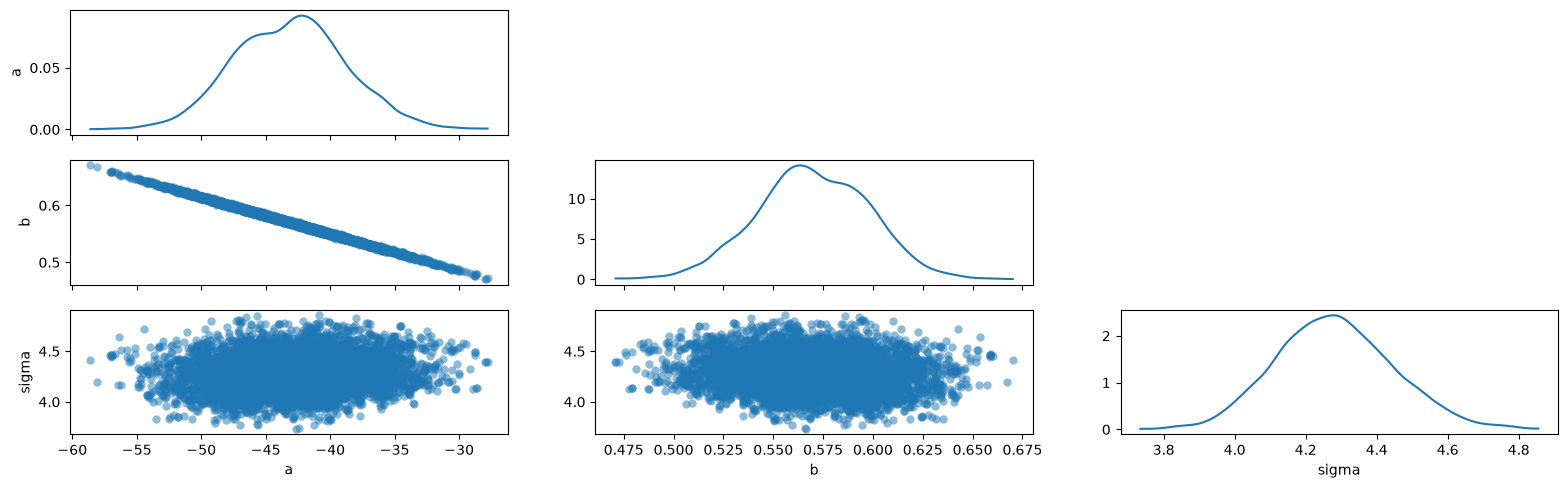

In [3]:
import arviz_plots as azp

azp.plot_pair(
    trace,
    var_names=["a", "b", "sigma"]
)

352


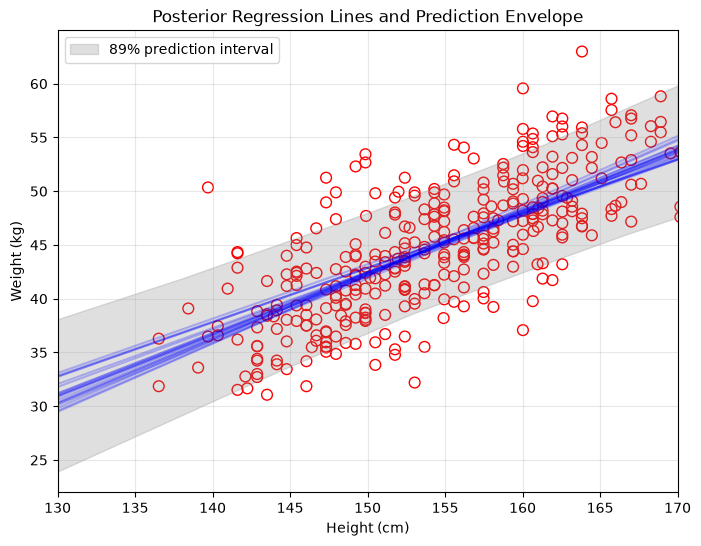

In [7]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

# Extract posterior samples
a_samples = trace.posterior["a"].values.flatten()
b_samples = trace.posterior["b"].values.flatten()
sigma_samples = trace.posterior["sigma"].values.flatten()

# Plot observed points
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    df["height"],
    df["weight"],
    facecolors="none",
    edgecolors="red",
    marker="o",
    s=60
)

# Height values for prediction
height_grid = np.linspace(130, 170, 100)

# Plot first 20 posterior regression lines
indices = np.arange(20)

for j in indices:
    ax.plot(
        height_grid,
        a_samples[j] + b_samples[j] * height_grid,
        color="blue",
        alpha=0.25,
        linewidth=1.5
    )

# Generate posterior predictive samples
mu = (
    a_samples[:, None]
    + b_samples[:, None] * height_grid
)

# Each regression line plus/minus its own sigma
lower = np.min(mu - sigma_samples[:, None], axis=0)
upper = np.max(mu + sigma_samples[:, None], axis=0)

# Draw envelope
ax.fill_between(
    height_grid,
    lower,
    upper,
    color="gray",
    alpha=0.25,
    label="89% prediction interval"
)

ax.set_xlim(130, 170)
ax.set_xlabel("Height (cm)")
ax.set_ylabel("Weight (kg)")
ax.set_title("Posterior Regression Lines and Prediction Envelope")
ax.grid(alpha=0.3)
ax.legend()

print(len(df))
plt.show()